In [1]:
#Credit Card Fraud Analysis


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("creditcard.csv")

In [5]:
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
df.shape

(284807, 31)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [29]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [9]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [10]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(1081)

In [12]:
#Understand the target variable

In [31]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [32]:
df['Class'].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [16]:
#Instead of showing: 0 and 1, follow below

In [33]:
df['Transaction_Type'] = df['Class'].map({
    0: 'Legitimate',
    1: 'Fraud'
})

In [34]:
df[['Class', 'Transaction_Type']].head()

,Class,Transaction_Type
0,0,Legitimate
1,0,Legitimate
2,0,Legitimate
3,0,Legitimate
4,0,Legitimate


In [19]:
#Create time features

In [35]:
df['Time_Hours'] = df['Time'] / 3600

In [36]:
df['Hour'] = (df['Time'] // 3600).astype(int)

In [24]:
#Amount analysis

In [37]:
df.groupby('Transaction_Type')['Amount'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
Transaction_Type,,,,,
Fraud,492,122.211321,9.25,0.0,2125.87
Legitimate,284315,88.291022,22.00,0.0,25691.16


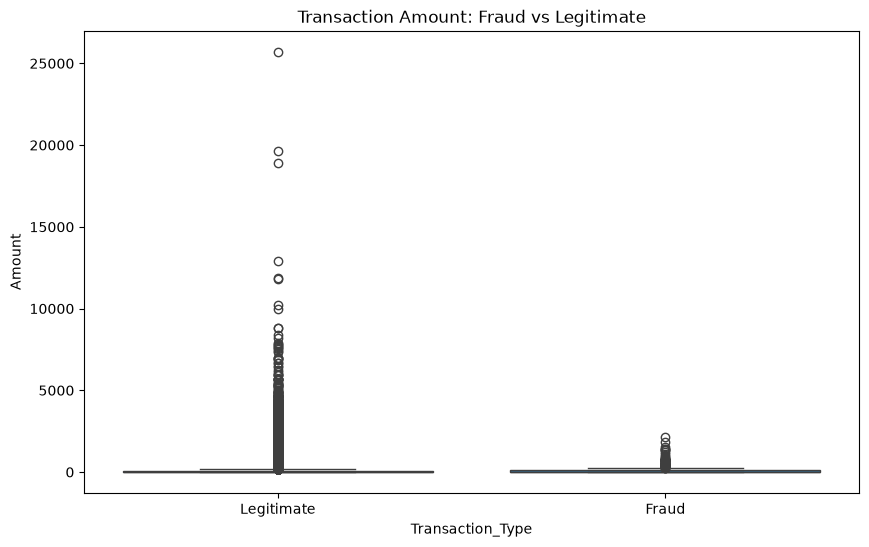

In [38]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x='Transaction_Type',
    y='Amount'
)

plt.title('Transaction Amount: Fraud vs Legitimate')
plt.show()

In [27]:
#Amount buckets

In [39]:
bins = [0, 10, 50, 100, 500, 1000, float('inf')]

labels = [
    '0-10',
    '10-50',
    '50-100',
    '100-500',
    '500-1000',
    '1000+'
]

df['Amount_Bucket'] = pd.cut(
    df['Amount'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [40]:
df.groupby('Amount_Bucket', observed=True)['Class'].agg(
    ['count', 'sum']
)

,count,sum
Amount_Bucket,,
0-10,100264,249
10-50,90781,57
50-100,37254,56
100-500,47366,95
500-1000,6202,26
1000+,2940,9


In [41]:
amount_analysis = df.groupby(
    'Amount_Bucket',
    observed=True
).agg(
    Transactions=('Class', 'count'),
    Fraud_Transactions=('Class', 'sum')
)

amount_analysis['Fraud_Rate'] = (
    amount_analysis['Fraud_Transactions'] /
    amount_analysis['Transactions']
) * 100

amount_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Amount_Bucket,,,
0-10,100264,249,0.248344
10-50,90781,57,0.062788
50-100,37254,56,0.150319
100-500,47366,95,0.200566
500-1000,6202,26,0.419220
1000+,2940,9,0.306122


In [31]:
#QUESTIONS

In [43]:
# 1. Time-based fraud analysis

In [42]:
df['Time_Period'] = pd.cut(
    df['Time'],
    bins=10,
    labels=False
)

In [43]:
time_analysis = df.groupby('Time_Period').agg(
    Transactions=('Class', 'count'),
    Fraud_Transactions=('Class', 'sum')
)

time_analysis['Fraud_Rate'] = (
    time_analysis['Fraud_Transactions'] /
    time_analysis['Transactions']
) * 100

time_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Time_Period,,,
0,10510,42,0.399619
1,16955,48,0.283102
2,38526,79,0.205056
3,38550,63,0.163424
4,40243,49,0.121760
5,10145,68,0.670281
6,17161,11,0.064099
7,38951,34,0.087289
8,40779,66,0.161848


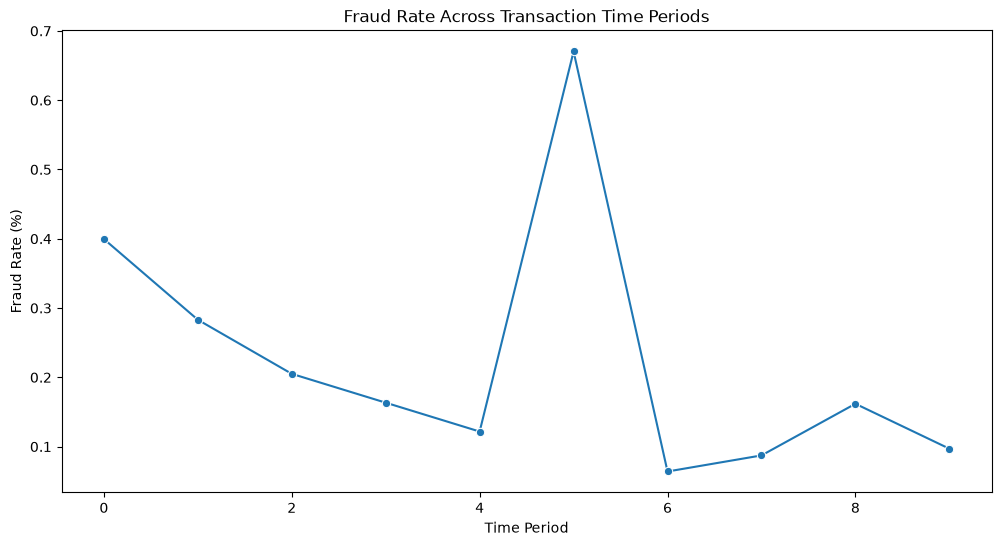

In [44]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=time_analysis,
    x=time_analysis.index,
    y='Fraud_Rate',
    marker='o'
)

plt.title('Fraud Rate Across Transaction Time Periods')
plt.xlabel('Time Period')
plt.ylabel('Fraud Rate (%)')

plt.show()

In [36]:
#V1 to V28 analysis

In [42]:
# 2. Which features differ most between fraudulent and legitimate transactions?

In [10]:
feature_cols = [f'V{i}' for i in range(1, 29)]

In [11]:
feature_means = df.groupby('Class')[feature_cols].mean().T

In [47]:
feature_means

Class,0,1
V1,0.008258,-4.771948
V2,-0.006271,3.623778
V3,0.012171,-7.033281
V4,-0.007860,4.542029
V5,0.005453,-3.151225
V6,0.002419,-1.397737
V7,0.009637,-5.568731
V8,-0.000987,0.570636
V9,0.004467,-2.581123
V10,0.009824,-5.676883


In [41]:
# 3.Correlation analysis

In [48]:
correlation = df.corr(numeric_only=True)['Class'].sort_values(
    ascending=False
)

In [49]:
correlation

Class          1.000000
V11            0.154876
V4             0.133447
V2             0.091289
V21            0.040413
V19            0.034783
V20            0.020090
V8             0.019875
V27            0.017580
V28            0.009536
Amount         0.005632
V26            0.004455
V25            0.003308
V22            0.000805
V23           -0.002685
V15           -0.004223
V13           -0.004570
V24           -0.007221
Time          -0.012323
Time_Hours    -0.012323
Hour          -0.012326
Time_Period   -0.012397
V6            -0.043643
V5            -0.094974
V9            -0.097733
V1            -0.101347
V18           -0.111485
V7            -0.187257
V3            -0.192961
V16           -0.196539
V10           -0.216883
V12           -0.260593
V14           -0.302544
V17           -0.326481
Name: Class, dtype: float64

In [46]:
#Identify suspicious patterns

In [55]:
# pattern1) Transaction Amount Analysis

In [54]:
#Creating amount buckets

In [50]:
bins = [0, 10, 50, 100, 500, 1000, float('inf')]

labels = [
    '0-10',
    '10-50',
    '50-100',
    '100-500',
    '500-1000',
    '1000+'
]

df['Amount_Bucket'] = pd.cut(
    df['Amount'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [51]:
df[['Amount', 'Amount_Bucket', 'Class']].head(20)

,Amount,Amount_Bucket,Class
0,149.62,100-500,0
1,2.69,0-10,0
2,378.66,100-500,0
3,123.50,100-500,0
4,69.99,50-100,0
5,3.67,0-10,0
6,4.99,0-10,0
7,40.80,10-50,0
8,93.20,50-100,0
9,3.68,0-10,0


In [26]:
amount_analysis = df.groupby(
    'Amount_Bucket',
    observed=True
).agg(
    Total_Transactions=('Class', 'count'),
    Fraud_Transactions=('Class', 'sum')
)

amount_analysis['Fraud_Rate'] = (
    amount_analysis['Fraud_Transactions']
    / amount_analysis['Total_Transactions']
) * 100

amount_analysis

,Total_Transactions,Fraud_Transactions,Fraud_Rate
Amount_Bucket,,,
0-10,100264,249,0.248344
10-50,90781,57,0.062788
50-100,37254,56,0.150319
100-500,47366,95,0.200566
500-1000,6202,26,0.419220
1000+,2940,9,0.306122


In [ ]:
#Pattern 2 — Time

In [52]:
df['Time_Period'] = pd.cut(
    df['Time'],
    bins=10,
    labels=False
)

In [53]:
time_analysis = df.groupby('Time_Period').agg(
    Total_Transactions=('Class', 'count'),
    Fraud_Transactions=('Class', 'sum')
)

time_analysis['Fraud_Rate'] = (
    time_analysis['Fraud_Transactions']
    / time_analysis['Total_Transactions']
) * 100

In [8]:
time_analysis

,Total_Transactions,Fraud_Transactions,Fraud_Rate
Time_Period,,,
0,10510,42,0.399619
1,16955,48,0.283102
2,38526,79,0.205056
3,38550,63,0.163424
4,40243,49,0.121760
5,10145,68,0.670281
6,17161,11,0.064099
7,38951,34,0.087289
8,40779,66,0.161848


In [9]:
#Pattern 3 — Behavioural / Feature Analysis

In [12]:
feature_cols = [f'V{i}' for i in range(1, 29)]

In [13]:
feature_means = df.groupby('Class')[feature_cols].mean().T

In [14]:
feature_comparison = pd.DataFrame({
    'Legitimate_Mean': feature_means[0],
    'Fraud_Mean': feature_means[1]
})

feature_comparison['Difference'] = (
    feature_comparison['Fraud_Mean']
    - feature_comparison['Legitimate_Mean']
).abs()

In [15]:
top_features = feature_comparison.sort_values(
    'Difference',
    ascending=False
).head(10)

top_features

,Legitimate_Mean,Fraud_Mean,Difference
V3,0.012171,-7.033281,7.045452
V14,0.012064,-6.971723,6.983787
V17,0.011535,-6.665836,6.677371
V12,0.010832,-6.259393,6.270225
V10,0.009824,-5.676883,5.686707
V7,0.009637,-5.568731,5.578368
V1,0.008258,-4.771948,4.780206
V4,-0.007860,4.542029,4.549889
V16,0.007164,-4.139946,4.147110
V11,-0.006576,3.800173,3.806749


In [27]:
# patern 4)Financial KPIs

In [58]:
total_transactions = len(df)

fraud_transactions = df['Class'].sum()

fraud_rate = df['Class'].mean() * 100

total_fraud_amount = df.loc[
    df['Class'] == 1,
    'Amount'
].sum()

average_fraud_amount = df.loc[
    df['Class'] == 1,
    'Amount'
].mean()

In [59]:
total_transactions 


284807

In [28]:
#Prepare Power BI dataset

In [60]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class', 'Transaction_Type', 'Time_Hours', 'Hour', 'Amount_Bucket',
       'Time_Period'],
      dtype='str')

In [61]:
df.to_csv("fraud_analysis_powerbi.csv", index=False)

In [62]:
import os

os.path.exists("fraud_analysis_powerbi.csv")

True

In [63]:
powerbi_df = pd.read_csv("fraud_analysis_powerbi.csv")

powerbi_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V26,V27,V28,Amount,Class,Transaction_Type,Time_Hours,Hour,Amount_Bucket,Time_Period
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.189115,0.133558,-0.021053,149.62,0,Legitimate,0.000000,0,100-500,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.125895,-0.008983,0.014724,2.69,0,Legitimate,0.000000,0,0-10,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,-0.139097,-0.055353,-0.059752,378.66,0,Legitimate,0.000278,0,100-500,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.221929,0.062723,0.061458,123.50,0,Legitimate,0.000278,0,100-500,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.502292,0.219422,0.215153,69.99,0,Legitimate,0.000556,0,50-100,0


In [64]:
powerbi_df.shape

(284807, 36)

In [65]:
df.columns.tolist()

['Time',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'Amount',
 'Class',
 'Transaction_Type',
 'Time_Hours',
 'Hour',
 'Amount_Bucket',
 'Time_Period']

In [68]:
feature_columns = [f'V{i}' for i in range(1, 29)]

powerbi_columns = [
    'Time',
    'Amount',
    'Class',
    'Amount_Bucket',
    'Time_Period'
] + feature_columns

powerbi_df = df[powerbi_columns].copy()

In [67]:
powerbi_df.head()

,Time,Amount,Class,Amount_Bucket,Time_Period,V1,V2,V3,V4,V5,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
0,0.0,149.62,0,100-500,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,...,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053
1,0.0,2.69,0,0-10,0,1.191857,0.266151,0.166480,0.448154,0.060018,...,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724
2,1.0,378.66,0,100-500,0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,...,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752
3,1.0,123.50,0,100-500,0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,...,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458
4,2.0,69.99,0,50-100,0,-1.158233,0.877737,1.548718,0.403034,-0.407193,...,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153


In [69]:
powerbi_df.shape

(284807, 33)

In [70]:
powerbi_df.columns.tolist()

['Time',
 'Amount',
 'Class',
 'Amount_Bucket',
 'Time_Period',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28']

In [71]:
powerbi_df.to_csv("fraud_analysis_powerbi.csv", index=False)

In [72]:
import os
os.path.exists("fraud_analysis_powerbi.csv")

True

In [73]:
df['Transaction_Type'] = df['Class'].map({
    0: 'Legitimate',
    1: 'Fraud'
})

In [74]:
df[['Class', 'Transaction_Type']].head(10)

,Class,Transaction_Type
0,0,Legitimate
1,0,Legitimate
2,0,Legitimate
3,0,Legitimate
4,0,Legitimate
5,0,Legitimate
6,0,Legitimate
7,0,Legitimate
8,0,Legitimate
9,0,Legitimate


In [75]:
feature_columns = [f'V{i}' for i in range(1, 29)]

powerbi_columns = [
    'Time',
    'Amount',
    'Class',
    'Transaction_Type',
    'Amount_Bucket',
    'Time_Period'
] + feature_columns

powerbi_df = df[powerbi_columns].copy()

In [76]:
powerbi_df.head()



,Time,Amount,Class,Transaction_Type,Amount_Bucket,Time_Period,V1,V2,V3,V4,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
0,0.0,149.62,0,Legitimate,100-500,0,-1.359807,-0.072781,2.536347,1.378155,...,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053
1,0.0,2.69,0,Legitimate,0-10,0,1.191857,0.266151,0.166480,0.448154,...,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724
2,1.0,378.66,0,Legitimate,100-500,0,-1.358354,-1.340163,1.773209,0.379780,...,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752
3,1.0,123.50,0,Legitimate,100-500,0,-0.966272,-0.185226,1.792993,-0.863291,...,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458
4,2.0,69.99,0,Legitimate,50-100,0,-1.158233,0.877737,1.548718,0.403034,...,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153


In [51]:
powerbi_df.shape

(284807, 34)

In [77]:
powerbi_df.columns.tolist()

['Time',
 'Amount',
 'Class',
 'Transaction_Type',
 'Amount_Bucket',
 'Time_Period',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28']

In [8]:
powerbi_df.to_csv("fraud_analysis_powerbi.csv", index=False)

NameError: name 'powerbi_df' is not defined

In [54]:
import os

os.path.exists("fraud_analysis_powerbi.csv")

True

In [1]:
import os

os.getcwd()

'C:\\Users\\Ayushi Rahangdale\\Fraud analysis.ipynb'

In [2]:
'C:\\Users\\YourName\\...'

'C:\\Users\\YourName\\...'

In [4]:
os.path.abspath("fraud_analysis_powerbi.csv")

'C:\\Users\\Ayushi Rahangdale\\Fraud analysis.ipynb\\fraud_analysis_powerbi.csv'

In [6]:
import os

os.path.join(os.path.expanduser("~"), "Downloads", "fraud_analysis_powerbi.csv")

'C:\\Users\\Ayushi Rahangdale\\Downloads\\fraud_analysis_powerbi.csv'

In [12]:
import os

downloads_path = os.path.join(
    os.path.expanduser("~"),
    "Downloads",
    "fraud_analysis_powerbi.csv"
)

powerbi_df.to_csv(downloads_path, index=False)

NameError: name 'powerbi_df' is not defined

In [78]:
import pandas as pd
import os

# Load original dataset
df = pd.read_csv("creditcard.csv")

# Create Transaction Type
df['Transaction_Type'] = df['Class'].map({
    0: 'Legitimate',
    1: 'Fraud'
})

# Create Amount Bucket
bins = [0, 10, 50, 100, 500, 1000, float('inf')]

labels = [
    '0-10',
    '10-50',
    '50-100',
    '100-500',
    '500-1000',
    '1000+'
]

df['Amount_Bucket'] = pd.cut(
    df['Amount'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Create Time Period
df['Time_Period'] = pd.cut(
    df['Time'],
    bins=10,
    labels=False
)

# Select columns for Power BI
feature_columns = [f'V{i}' for i in range(1, 29)]

powerbi_columns = [
    'Time',
    'Amount',
    'Class',
    'Transaction_Type',
    'Amount_Bucket',
    'Time_Period'
] + feature_columns

powerbi_df = df[powerbi_columns].copy()

# Export directly to Downloads
downloads_path = os.path.join(
    os.path.expanduser("~"),
    "Downloads",
    "fraud_analysis_powerbi.csv"
)

powerbi_df.to_csv(downloads_path, index=False)

# Confirmation
print("Power BI dataset created successfully!")
print("Shape:", powerbi_df.shape)
print("File location:", downloads_path)
print("File exists:", os.path.exists(downloads_path))

Power BI dataset created successfully!
Shape: (284807, 34)
File location: C:\Users\Ayushi Rahangdale\Downloads\fraud_analysis_powerbi.csv
File exists: True


In [16]:
# Create Feature Summary for Power BI Page 2

feature_summary = feature_comparison.reset_index()

feature_summary = feature_summary.rename(
    columns={'index': 'Feature'}
)

feature_summary.to_csv(
    r"C:\Users\Ayushi Rahangdale\Downloads\feature_summary.csv",
    index=False
)

print("Feature summary exported successfully!")
print(feature_summary.shape)
print(feature_summary.head())

Feature summary exported successfully!
(28, 4)
  Feature  Legitimate_Mean  Fraud_Mean  Difference
0      V1         0.008258   -4.771948    4.780206
1      V2        -0.006271    3.623778    3.630049
2      V3         0.012171   -7.033281    7.045452
3      V4        -0.007860    4.542029    4.549889
4      V5         0.005453   -3.151225    3.156678
